# Error analysis

Dev predictions of B0, E0, E1 and E2 (once its run exists), greedy decoding.

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.training.errors import CATEGORIES, classify
from src.training.evaluate import read_jsonl

RUNS = {"B0": "b0_retrieval/char", "E0": "e0_lstm", "E1": "e1_attn", "E2": "e2_copy"}
RUNS = {m: ROOT / "experiments" / r for m, r in RUNS.items() if (ROOT / "experiments" / r / "metrics.json").exists()}
LOCALES = ["overall", "en-US", "fr-FR", "ar-SA"]

metrics = {m: pd.read_json(d / "metrics.json", typ="series") for m, d in RUNS.items()}
preds = {m: pd.DataFrame(read_jsonl(d / "predictions_dev.jsonl.gz")) for m, d in RUNS.items()}
list(RUNS)

['B0', 'E0', 'E1', 'E2']

Headline numbers per locale (%).

In [2]:
KEYS = {"exact_match": "EM", "exact_match_strict": "EM strict", "intent_accuracy": "intent",
        "slot_f1": "slot F1", "valid_call_rate": "valid", "macro_exact_match": "macro EM"}
table = pd.DataFrame([
    {"model": m, "locale": loc, **{short: 100 * metrics[m]["results"][loc][k] for k, short in KEYS.items()}}
    for loc in LOCALES for m in RUNS
]).set_index(["locale", "model"])
table.round(1)

EM  EM strict  intent  slot F1  valid  macro EM
locale  model                                                   
overall B0     35.2       34.6    69.6     44.1  100.0      38.8
        E0     44.4       44.2    80.6     47.9  100.0      47.0
        E1     45.8       45.7    80.6     52.1  100.0      47.7
        E2     57.6       57.6    80.5     70.1  100.0      57.6
en-US   B0     40.4       39.7    72.7     51.5  100.0      44.7
        E0     47.9       47.7    83.3     52.1  100.0      51.7
        E1     50.3       50.3    84.2     56.4  100.0      52.4
        E2     64.1       64.1    84.5     75.4  100.0      64.1
fr-FR   B0     33.1       32.5    70.6     40.9  100.0      37.4
        E0     45.3       45.2    82.4     48.3  100.0      47.1
        E1     46.1       46.1    82.1     52.1  100.0      48.1
        E2     57.6       57.6    81.8     69.3  100.0      58.1
ar-SA   B0     32.2       31.6    65.6     39.7  100.0      34.5
        E0     40.0       39.8    76.1     43.0  100.0      42.3
        E1     40.9       40.8    75.5     47.6  100.0      42.6
        E2     51.2       51.2    75.3     65.5  100.0      50.7

Seen = the utterance appears verbatim in the train split of the same locale.

In [3]:
rows = []
for loc in LOCALES:
    for m in RUNS:
        su = metrics[m]["seen_unseen"][loc]
        for part in ("seen", "unseen"):
            r = su[part]
            rows.append({"locale": loc, "model": m, "subset": part, "n": r["n"],
                         "EM": 100 * r["exact_match"], "intent": 100 * r["intent_accuracy"],
                         "slot F1": 100 * r["slot_f1"]})
pd.DataFrame(rows).pivot_table(index=["locale", "model"], columns="subset",
                               values=["n", "EM", "slot F1"]).round(1)

EM             n         slot F1       
subset         seen unseen   seen  unseen    seen unseen
locale  model                                           
ar-SA   B0     79.2   28.5  149.0  1884.0    93.5   36.4
        E0     82.6   36.6  149.0  1884.0    93.1   40.1
        E1     78.5   38.0  149.0  1884.0    93.5   44.9
        E2     82.6   48.7  149.0  1884.0    94.1   63.9
en-US   B0     90.9   40.1   11.0  2022.0   100.0   51.3
        E0     63.6   47.8   11.0  2022.0    73.7   52.0
        E1     72.7   50.2   11.0  2022.0    77.8   56.3
        E2     81.8   64.0   11.0  2022.0    94.7   75.3
fr-FR   B0     88.8   30.3   98.0  1935.0    93.6   39.2
        E0     89.8   43.0   98.0  1935.0    93.6   47.0
        E1     86.7   44.1   98.0  1935.0    90.9   51.0
        E2     90.8   55.9   98.0  1935.0    94.5   68.6
overall B0     83.3   33.1  258.0  5841.0    93.9   42.5
        E0     84.5   42.6  258.0  5841.0    92.2   46.5
        E1     81.4   44.2  258.0  5841.0    91.9   50.9
        E2     85.7   56.4  258.0  5841.0    94.3   69.4

Exact match per intent against the number of train examples (overall dev, one point per intent).

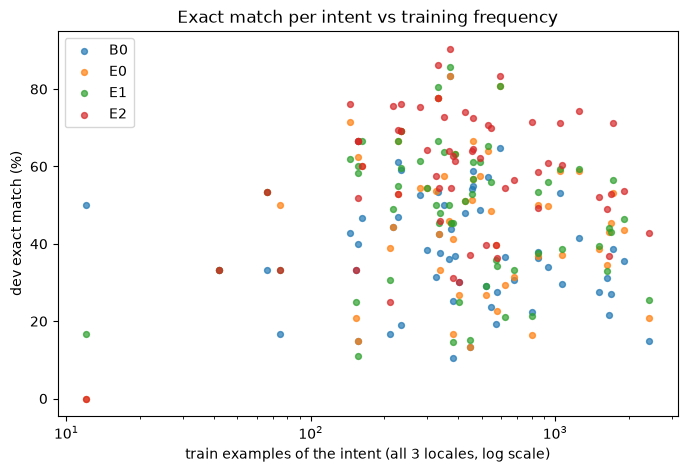

{'B0': np.float64(-0.21),
 'E0': np.float64(-0.2),
 'E1': np.float64(-0.13),
 'E2': np.float64(-0.0)}

In [4]:
per_intent = pd.concat([
    pd.DataFrame(metrics[m]["results"]["overall"]["per_intent"]).T.assign(model=m) for m in RUNS
])
per_intent["n_train"] = per_intent["n_train"].astype(int)

fig, ax = plt.subplots(figsize=(8, 5))
for m, sub in per_intent.groupby("model", sort=False):
    ax.scatter(sub["n_train"], 100 * sub["exact_match"].astype(float), label=m, alpha=0.7, s=18)
ax.set(xscale="log", xlabel="train examples of the intent (all 3 locales, log scale)",
       ylabel="dev exact match (%)", title="Exact match per intent vs training frequency")
ax.legend()
plt.show()

# spearman = pearson on ranks (no scipy needed)
{m: round(sub["n_train"].rank().corr(sub["exact_match"].astype(float).rank()), 2)
 for m, sub in per_intent.groupby("model", sort=False)}

The EM correlation mixes two things: how well the intent is recognized, and how hard its calls are. Frequent intents also have more and longer slots, and every slot is a chance to miss exact match.

In [5]:
from scipy.stats import spearmanr

from src.data.dataset import load_split

train = pd.DataFrame(load_split(ROOT / "data" / "massive", ["en-US", "fr-FR", "ar-SA"], "train"))
train["n_slots"] = train["slots"].str.len()
train["value_words"] = train["slots"].apply(lambda s: sum(len(v.split()) for _, v in s))
props = train.groupby("intent").agg(slots_per_call=("n_slots", "mean"), value_words=("value_words", "mean"))

rows = []
for m in RUNS:
    df = per_intent[per_intent["model"] == m].join(props)
    for score in ["exact_match", "intent_f1"]:
        rho, pval = spearmanr(df["n_train"], df[score].astype(float))
        rows.append({"model": m, "n_train vs": score, "spearman": rho, "p": pval})
for c in ["slots_per_call", "value_words"]:
    rho, pval = spearmanr(df["n_train"], df[c])
    rows.append({"model": "-", "n_train vs": c, "spearman": rho, "p": pval})
    rho, pval = spearmanr(per_intent[per_intent["model"] == "E1"].join(props)[c],
                          per_intent[per_intent["model"] == "E1"]["exact_match"].astype(float))
    rows.append({"model": "E1", "n_train vs": f"(EM vs {c})", "spearman": rho, "p": pval})
pd.DataFrame(rows).round(2)

,model,n_train vs,spearman,p
0,B0,exact_match,-0.21,0.12
1,B0,intent_f1,0.10,0.44
2,E0,exact_match,-0.20,0.14
3,E0,intent_f1,0.27,0.04
4,E1,exact_match,-0.13,0.31
5,E1,intent_f1,0.28,0.03
6,E2,exact_match,-0.00,0.97
7,E2,intent_f1,0.37,0.00
8,-,slots_per_call,0.31,0.02
9,E1,(EM vs slots_per_call),-0.50,0.00


Weakest and strongest intents for the best model.

In [6]:
best = max(RUNS, key=lambda m: metrics[m]["results"]["overall"]["exact_match"])
cols = ["n_train", "n", "intent_recall", "exact_match", "slot_f1"]
ranked = per_intent[per_intent["model"] == best][cols].astype(float).sort_values("exact_match")
print("best model:", best)
pd.concat([ranked.head(8), ranked.tail(5)]).round(2)

best model: E2


,n_train,n,intent_recall,exact_match,slot_f1
cooking_query,12.0,6.0,0.00,0.00,0.00
recommendation_movies,210.0,36.0,0.58,0.25,0.51
takeaway_order,405.0,60.0,0.67,0.30,0.41
email_querycontact,381.0,48.0,0.67,0.31,0.57
music_settings,153.0,24.0,0.75,0.33,0.52
music_dislikeness,42.0,6.0,0.33,0.33,0.00
general_greet,75.0,6.0,0.33,0.33,NaN
play_podcasts,579.0,102.0,0.79,0.36,0.37
iot_wemo_on,144.0,21.0,0.90,0.76,0.82
audio_volume_mute,330.0,45.0,0.82,0.78,0.36


Error types: each prediction gets the first category that applies (see `src/training/errors.py`). % of all dev examples.

In [7]:
for m, p in preds.items():
    p["error"] = [classify(pr, g) for pr, g in zip(p["pred"], p["gold"])]
errors = pd.DataFrame({m: p["error"].value_counts(normalize=True) * 100 for m, p in preds.items()})
errors.reindex(CATEGORIES).fillna(0).round(1)

,B0,E0,E1,E2
error,,,,
correct,35.2,44.4,45.8,57.6
invalid call,0.0,0.0,0.0,0.0
wrong intent,30.4,19.4,19.4,19.5
missing slot,14.3,7.0,6.6,5.3
extra slot,6.1,6.4,7.1,6.6
wrong slot names,4.3,6.8,6.0,5.6
value with <UNK>,0.0,6.6,6.7,0.0
repeated copy,0.0,0.0,0.1,0.4
value partly wrong,5.0,4.4,4.8,4.4


Same breakdown per locale for the best model.

In [8]:
p = preds[best]
(pd.crosstab(p["error"], p["locale"], normalize="columns") * 100).reindex(CATEGORIES).fillna(0).round(1)

locale,ar-SA,en-US,fr-FR
error,,,
correct,51.2,64.1,57.6
invalid call,0.0,0.0,0.0
wrong intent,24.7,15.5,18.2
missing slot,6.4,4.0,5.5
extra slot,6.8,6.1,6.8
wrong slot names,5.9,6.3,4.7
value with <UNK>,0.0,0.0,0.0
repeated copy,0.3,0.3,0.6
value partly wrong,4.0,3.3,5.9


One example per error type and locale for the best model.

In [9]:
pd.set_option("display.max_colwidth", 80)
examples = (p[p["error"] != "correct"].groupby(["error", "locale"], sort=False).head(1)
            .sort_values(["error", "locale"])[["locale", "error", "utt", "gold", "pred"]])
examples

,locale,error,utt,gold,pred
4066,ar-SA,extra slot,طفي اللمبات الله يسعدك,iot_hue_lightoff(),"iot_hue_lightoff(device_type=""اللمبات"", change_amount=""الله يسعدك"")"
11,en-US,extra slot,what's with my dinner order,takeaway_query(),"takeaway_query(meal_type=""dinner"")"
2042,fr-FR,extra slot,jouer moi jacques brel ne me quitte pas,play_music(),"play_music(artist_name=""jacques brel"", song_name=""ne me quitte pas"")"
4067,ar-SA,missing slot,وطي اللمبات في الممر,"iot_hue_lightdim(house_place=""الممر"")",iot_hue_lightdim()
8,en-US,missing slot,i'd like to hear queen's barcelona,"play_music(artist_name=""queen's"", song_name=""barcelona"")","play_music(artist_name=""queen's barcelona"")"
2050,fr-FR,missing slot,règle le volume sur le niveau bas,"audio_volume_down(change_amount=""bas"")",audio_volume_down()
4356,ar-SA,repeated copy,حط منبه عالساعة ثمانية بكره الصبح,"alarm_set(time=""ثمانية"", date=""بكره"", timeofday=""الصبح"")","alarm_set(time=""ثمانية ثمانية"", date=""بكره"", timeofday=""الصبح"")"
448,en-US,repeated copy,what are the scores for the two ucl games going on right now,"news_query(news_topic=""two ucl games"")","news_query(news_topic=""the ucl ucl"")"
2074,fr-FR,repeated copy,quel jour de la semaine tombe le vingt deux mars,"datetime_query(date=""vingt deux mars"")","datetime_query(date=""le deux deux mars"")"
4082,ar-SA,value partly wrong,كرر تشغيل هذا track,"music_settings(player_setting=""كرر تشغيل"")","music_settings(player_setting=""كرر"")"


Attention of E1 on three dev examples it gets right (teacher-forced on the gold call). Arabic tokens are shown by position because matplotlib doesn't shape Arabic text; the tokens are printed below.

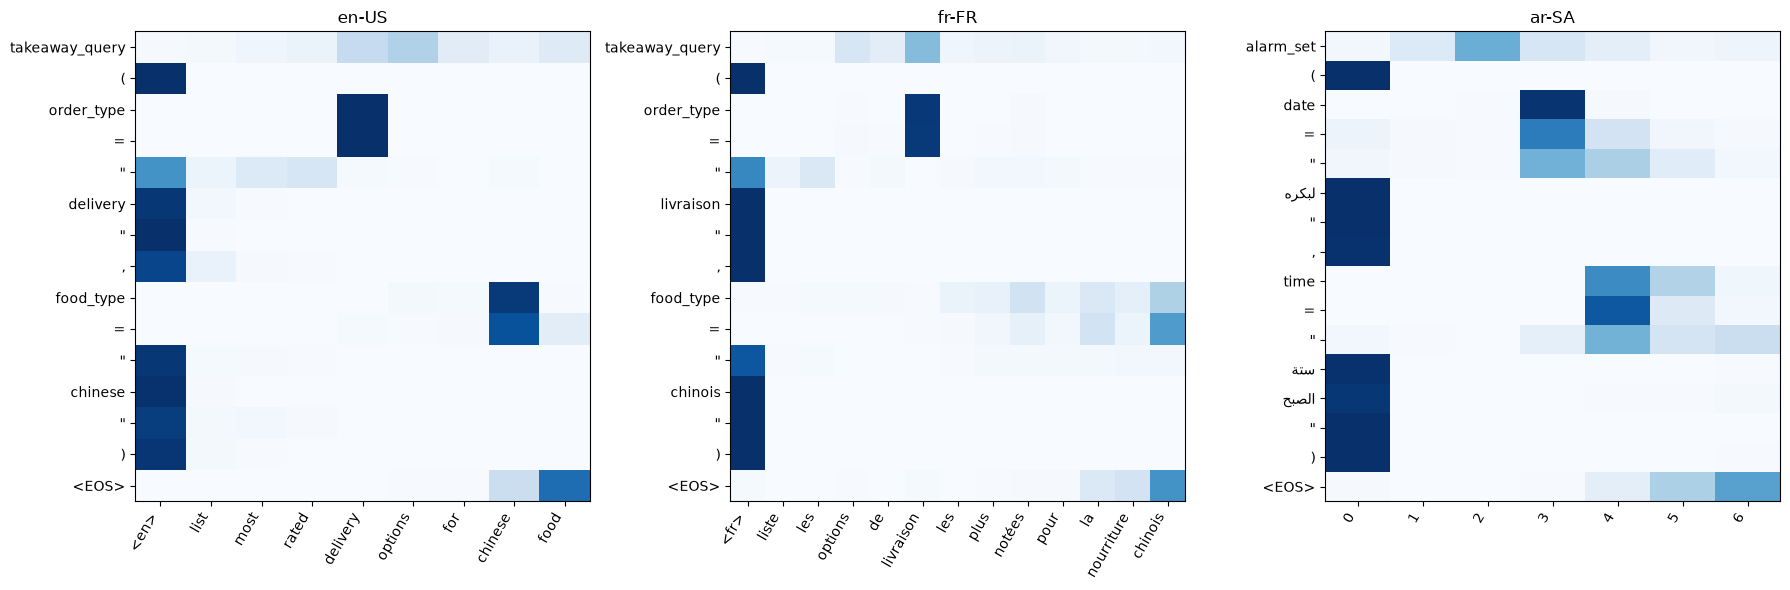

ar-SA source tokens: [(0, 'حط'), (1, 'منبه'), (2, 'لبكره'), (3, 'الساعة'), (4, 'ستة'), (5, 'الصبح')]
calls: ['takeaway_query(order_type="delivery", food_type="chinese")', 'takeaway_query(order_type="livraison", food_type="chinois")', 'alarm_set(date="لبكره", time="ستة الصبح")']


In [10]:
import yaml

from src.data.dataset import MassiveDataset, collate, load_split
from src.data.vocab import Vocab
from src.training.train import build_model

e1_dir = ROOT / "experiments" / "e1_attn"
cfg = yaml.safe_load((e1_dir / "config.yaml").read_text(encoding="utf-8"))
src_vocab, tgt_vocab = Vocab.load(e1_dir / "vocab_src.json"), Vocab.load(e1_dir / "vocab_tgt.json")
model = build_model(cfg, len(src_vocab), len(tgt_vocab))
model.load_state_dict(torch.load(e1_dir / "model.pt", map_location="cpu"))
model.eval()

dev = {(r["locale"], r["id"]): r for r in load_split(ROOT / "data" / "massive", ["en-US", "fr-FR", "ar-SA"], "dev")}
e1 = preds["E1"]
chosen = []
for loc in ["en-US", "fr-FR", "ar-SA"]:
    ok = e1[(e1["locale"] == loc) & (e1["pred"] == e1["gold"])]
    row = next(dev[(loc, i)] for i in ok["id"] if len(dev[(loc, i)]["slots"]) >= 2)
    chosen.append(row)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, row in zip(axes, chosen):
    ds = MassiveDataset([row], src_vocab, tgt_vocab, lang_tag=cfg["data"]["lang_tag"])
    batch = collate([ds[0]])
    with torch.no_grad():
        _, attn = model(batch["src"], batch["src_lens"], batch["tgt"][:, :-1], return_attn=True)
    src_toks = batch["src_tokens"][0]
    tgt_toks = row["target_tokens"] + ["<EOS>"]
    ax.imshow(attn[0].numpy(), cmap="Blues", aspect="auto")
    xlabels = [str(i) for i in range(len(src_toks))] if row["locale"] == "ar-SA" else src_toks
    ax.set_xticks(range(len(src_toks)), xlabels, rotation=60, ha="right")
    ax.set_yticks(range(len(tgt_toks)), tgt_toks)
    ax.set_title(row["locale"])
plt.tight_layout()
plt.show()
print("ar-SA source tokens:", list(enumerate(chosen[2]["src_tokens"])))
print("calls:", [r["call"] for r in chosen])

## Takeaways

- E2 (copy) is clearly the best: 57.6% dev EM overall (EN 64.1, FR 57.6, AR 51.2), against 45.8% for E1, 44.4% for E0 and 35.2% for B0. Almost all of the gain is on arguments: slot F1 goes from 52.1 (E1) to 70.1, while intent accuracy stays at 80.5%.
- Copy removes the value errors it was built for: values with <UNK> go from 6.7% of dev (E1) to 0, and completely wrong values from 3.6% to 0.6%. Repeated copies like "am am" go up from 0.1% to 0.4% (24 calls, 12 of them French), e.g. "the ucl ucl" for "two ucl games". It's a known pointer-generator failure; coverage would target it.
- Wrong intent is now the main problem: 19.5% of dev for E2, the same as E0 and E1 (24.7% in Arabic, 15.5% in English). None of the decoder changes touch it, so the next gains have to come from the encoder side (multilingual training, subwords for Arabic) rather than from decoding.
- The 258 seen utterances stay easy (85.7% EM for E2). On unseen ones E2 gets 56.4% EM against 44.2% for E1 and 33.1% for B0.
- The rank correlation between n_train and per-intent EM is -0.21 (B0), -0.20 (E0), -0.13 (E1), 0.00 (E2), none of them significant (p >= 0.12). The negative sign is a confounder: frequent intents have more slots per call (+0.31) and longer values (+0.26), and EM drops with both (-0.50 and -0.45 for E1). Recognizing the intent does get better with more data: n_train vs intent F1 is +0.27 (E0), +0.28 (E1), +0.37 (E2), all with p <= 0.04. E2 reaches 0.00 on EM because copying makes long values cheap, so the two effects cancel. The weakest E2 intents are rare or have long free-text values: cooking_query 0% (12 train examples), recommendation_movies 25%, takeaway_order 30%, email_querycontact 31%.
- Beam search on E2 adds 0.6 point: 58.2% EM with beam 3, 5 or 10 (same result), against 57.6% greedy. Beam 5 fixes 54 calls and breaks 19. I'll use beam 3, it decodes dev in 14.6 s against 43.7 s for beam 10.
- No model produces an invalid call on dev, so grammar-constrained decoding has nothing to fix there.
- In the heatmaps E1 attends to a value word one step early, while it writes the slot name and "=" (order_type -> "delivery", date -> لبكره), and parks on the language tag while writing the value itself. With Bahdanau attention the query is the previous state, so the information has to arrive a step ahead and go through the LSTM. Copying needs the weights on the right word at the right step, which E2 learns.
